question 1 

write a program for quadratic equation kcX^2 - (kc +1)X + 0.25kc = 0 
find discriminant selects the physically meaningful root (0<=X<=0.5)

prints eqb A B C 3 decimals and conversion of limiting rectant = X/A0 * 100%
now classify usiong if elif else: =>70 "high. =>40"moderate", otherwise low

In [1]:
import math

kc = float(input("Enter kc: "))
A0 = 0.5  # Initial limiting-reactant concentration in mol/L.
if A0 <= 0:
    raise ValueError("A0 must be greater than zero.")

a = kc
b = -(kc + 1)
c = 0.25 * kc

print(f"A = {a:.3f}, B = {b:.3f}, C = {c:.3f}")
if kc == 0:
    print("No quadratic equation because kc = 0.")
else:
    print(f"Equation: ({a:.3f})X^2 + ({b:.3f})X + ({c:.3f}) = 0")

discriminant = b**2 - 4 * a * c
print(f"Discriminant: {discriminant:.3f}")

if a == 0:
    # The equation becomes -X = 0 when kc is zero.
    roots = [0.0]
elif discriminant < 0:
    roots = []
else:
    sqrt_discriminant = math.sqrt(discriminant)
    roots = [
        (-b + sqrt_discriminant) / (2 * a),
        (-b - sqrt_discriminant) / (2 * a),
    ]

physical_roots = [root for root in roots if 0 <= root <= 0.5]

if physical_roots:
    for X in physical_roots:
        conversion = X / A0 * 100
        print(f"Physically meaningful root: X = {X:.3f} mol/L")
        print(f"Limiting-reactant conversion: {conversion:.3f}%")
        if conversion >= 70:
            print("Conversion classification: high")
        elif conversion >= 40:
            print("Conversion classification: moderate")
        else:
            print("Conversion classification: low")
else:
    print("No real root in the physical range 0 <= X <= 0.5.")

A = 0.500, B = -1.500, C = 0.125
Equation: (0.500)X^2 + (-1.500)X + (0.125) = 0
Discriminant: 2.000
Physically meaningful root: X = 0.086 mol/L
Limiting-reactant conversion: 17.157%
Conversion classification: low


question 2 part A

in a first order reaction, dC/dt = -kc use euler method: C_new - C_old - kC_old delta t take C0 = 1 mol/l k = 0,12/min delta t = 0.5 min 
using a for lop stimulate 5 minutes and print a table of time (min) concetration(mol/L) and conversion %
using math.exp(), calculate the exact value of C0e^9-kt) at 5 min and print th e absolulte error og the  euler result 

write a program

in the same code add
using a while loop repeat the stimulation until conversion reaches 70 % ot time reaches 100 min . print the time needed and final concentration



In [1]:
import math

C0 = 1.0       # Initial concentration (mol/L)
k = 0.12       # Rate constant (1/min)
delta_t = 0.5  # Time step (min)
total_time = 5.0

# Euler simulation for the first 5 minutes
steps = int(total_time / delta_t)
concentration = C0

print(f"{'Time (min)':>10} {'Concentration (mol/L)':>24} {'Conversion (%)':>18}")

for step in range(steps + 1):
    time = step * delta_t
    conversion = (C0 - concentration) / C0 * 100
    print(f"{time:10.1f} {concentration:24.4f} {conversion:18.2f}")

    if step < steps:
        concentration -= k * concentration * delta_t

exact_concentration = C0 * math.exp(-k * total_time)
absolute_error = abs(exact_concentration - concentration)

print(f"\nExact concentration at {total_time:.1f} min: "
      f"{exact_concentration:.6f} mol/L")
print(f"Absolute error of Euler result: {absolute_error:.6f} mol/L")

# Continue a separate simulation until 70% conversion or 100 minutes
concentration = C0
time = 0.0
conversion = 0.0
target_conversion = 70.0
max_time = 100.0

while conversion < target_conversion and time < max_time:
    concentration -= k * concentration * delta_t
    time += delta_t
    conversion = (C0 - concentration) / C0 * 100

print(f"\nTime needed: {time:.1f} min")
print(f"Final concentration: {concentration:.6f} mol/L")
print(f"Final conversion: {conversion:.2f}%")

Time (min)    Concentration (mol/L)     Conversion (%)
       0.0                   1.0000               0.00
       0.5                   0.9400               6.00
       1.0                   0.8836              11.64
       1.5                   0.8306              16.94
       2.0                   0.7807              21.93
       2.5                   0.7339              26.61
       3.0                   0.6899              31.01
       3.5                   0.6485              35.15
       4.0                   0.6096              39.04
       4.5                   0.5730              42.70
       5.0                   0.5386              46.14

Exact concentration at 5.0 min: 0.548812 mol/L
Absolute error of Euler result: 0.010197 mol/L

Time needed: 10.0 min
Final concentration: 0.290106 mol/L
Final conversion: 70.99%


question 2 part B

write a program that reads a code, loops through each character and print  the number of digits and the sum of digits show a message for an empty code and for a code with no digits 

In [3]:
code = input("Enter a code: ")
print(f"You entered: {code}")

if code == "":
    print("The code is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in code:
        if character in "0123456789":
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("The code contains no digits.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")

You entered: 
The code is empty.


question 3 part A


 plant has n candidates feed component and wants to blend r of them (orders does not matter ). write the recursive function fectorial (n)(remember the base case fopr 0!)and a function combinition(n,r) = n!/(r!(n-r)!) that uses it . reject invalid ( negative values,r>n

In [4]:


def factorial(n):
    if n < 0:
        raise ValueError("Factorial is not defined for negative integers.")
    if n == 0:  # Base case: 0! = 1
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0 or r > n:
        raise ValueError("Values must satisfy n >= 0 and 0 <= r <= n.")
    return factorial(n) // (factorial(r) * factorial(n - r))


n = int(input("Enter the number of candidate feed components (n): "))
r = int(input("Enter how many components to blend (r): "))

try:
    print(f"The number of combinations is {combination(n, r)}")
except ValueError as error:
    print(f"Invalid input: {error}")

The number of combinations is 70


question 3 part B

during a cooling experiment, temperature readings are taken at times = fibonacci number * 3 min. write an iteerative function fib_iter(n) that return the list of first n fibonacci function number, and a recursive function fib_rec(k) that returns the k th fibonacci ( f0 = 0, f1 = 1) for n = 8 check that functions agree
print a table: reading no. | fibonacci tag | time (min)

In [2]:
def fib_iter(n):
    """Return the first n Fibonacci numbers, starting with 0, 1."""
    if n < 0:
        raise ValueError("n must be non-negative")

    numbers = []
    a, b = 0, 1

    for _ in range(n):
        numbers.append(a)
        a, b = b, a + b

    return numbers


def fib_rec(k):
    """Return the kth Fibonacci number, with F0 = 0 and F1 = 1."""
    if k < 0:
        raise ValueError("k must be non-negative")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 8
iterative_values = fib_iter(n)
recursive_values = [fib_rec(k) for k in range(n)]

if iterative_values != recursive_values:
    raise RuntimeError("The iterative and recursive results do not match.")

print("The iterative and recursive results agree.")
print(f"{'Reading no.':>11} | {'Fibonacci tag':>13} | {'Time (min)':>10}")

for reading, (tag, value) in enumerate(zip(range(n), iterative_values), start=1):
    print(f"{reading:11} | F{tag} = {value:<8} | {value * 3:10}")

The iterative and recursive results agree.
Reading no. | Fibonacci tag | Time (min)
          1 | F0 = 0        |          0
          2 | F1 = 1        |          3
          3 | F2 = 1        |          3
          4 | F3 = 2        |          6
          5 | F4 = 3        |          9
          6 | F5 = 5        |         15
          7 | F6 = 8        |         24
          8 | F7 = 13       |         39


question 4 

the concentration (mol/L) was recorded as:
time_min ( 0, 10, 20, 30, 40, 50)
run1_mol_L(low UV) (o.8, 0.54, 0.36, 0.24, 0.16, 0.11)
run2_mol_L(high UV) (0.8, 0.44, 0.24, 0.13, 0.07, 0.04)


create a data frame from this table save it as kinectics,csv and kinetics.json read the CSV back and print its shape and data types 

print the mean and standard deviation of Run1 and Run2 and state which runs more variation 
plot both on graph time on x axis with title axis label with units legends and grid

In [14]:
import pandas as pd

# Interpreting "o.8" as 0.8; the remaining values are entered as provided.
data = {
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L_low_UV": [0.8, 0.54, 0.36, 0.24, 0.16, 0.11],
    "Run2_mol_L_high_UV": [0.8, 0.44, 0.24, 0.13, 0.7, 0.4],
}

kinetics = pd.DataFrame(data)

# Save the data in CSV and JSON formats
kinetics.to_csv("kinetics.csv", index=False)
kinetics.to_json("kinetics.json", orient="records", indent=4)

# Read the CSV back and display its shape and data types
kinetics_from_csv = pd.read_csv("kinetics.csv")

print("Shape:", kinetics_from_csv.shape)
print("\nData types:")
print(kinetics_from_csv.dtypes)

Shape: (6, 3)

Data types:
Time_min                int64
Run1_mol_L_low_UV     float64
Run2_mol_L_high_UV    float64
dtype: object


CSV shape: (6, 3)

Data types:
time_min                int64
run1_mol_L_low_UV     float64
run2_mol_L_high_UV    float64
dtype: object

Run 1 mean: 0.3683 mol/L
Run 1 standard deviation: 0.2617 mol/L
Run 2 mean: 0.2867 mol/L
Run 2 standard deviation: 0.2904 mol/L
Run 2 has more variation.


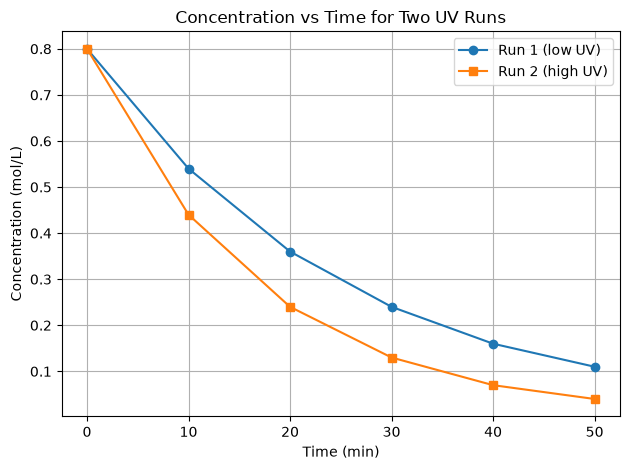

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "time_min": [0, 10, 20, 30, 40, 50],
    "run1_mol_L_low_UV": [0.8, 0.54, 0.36, 0.24, 0.16, 0.11],
    "run2_mol_L_high_UV": [0.8, 0.44, 0.24, 0.13, 0.07, 0.04],
}

df = pd.DataFrame(data)

# Save the data in both formats
df.to_csv("kinetics.csv", index=False)
df.to_json("kinetics.json", orient="records", indent=2)

# Read the CSV back and show its shape and data types
read_df = pd.read_csv("kinetics.csv")
print("CSV shape:", read_df.shape)
print("\nData types:")
print(read_df.dtypes)

# Calculate and print mean and sample standard deviation
run1_mean = read_df["run1_mol_L_low_UV"].mean()
run1_std = read_df["run1_mol_L_low_UV"].std()
run2_mean = read_df["run2_mol_L_high_UV"].mean()
run2_std = read_df["run2_mol_L_high_UV"].std()

print(f"\nRun 1 mean: {run1_mean:.4f} mol/L")
print(f"Run 1 standard deviation: {run1_std:.4f} mol/L")
print(f"Run 2 mean: {run2_mean:.4f} mol/L")
print(f"Run 2 standard deviation: {run2_std:.4f} mol/L")

if run1_std > run2_std:
    print("Run 1 has more variation.")
elif run2_std > run1_std:
    print("Run 2 has more variation.")
else:
    print("Both runs have the same variation.")

# Plot concentrations over time
plt.plot(read_df["time_min"], read_df["run1_mol_L_low_UV"], marker="o",
         label="Run 1 (low UV)")
plt.plot(read_df["time_min"], read_df["run2_mol_L_high_UV"], marker="s",
         label="Run 2 (high UV)")

plt.title("Concentration vs Time for Two UV Runs")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

question 4 part d 

Volume_L": [2, 3, 4, 5, 6],
    "pressure_bar ": [3.01, 1.98, 1.52, 1.19, 1.01]
}

 plot a pressure vs volume as a scatter plot calcu;late k as the mean of P * V and draw the reference the curve P = k/V on the same graph add title labels with units and legends 

Mean k: 6.01 bar·L


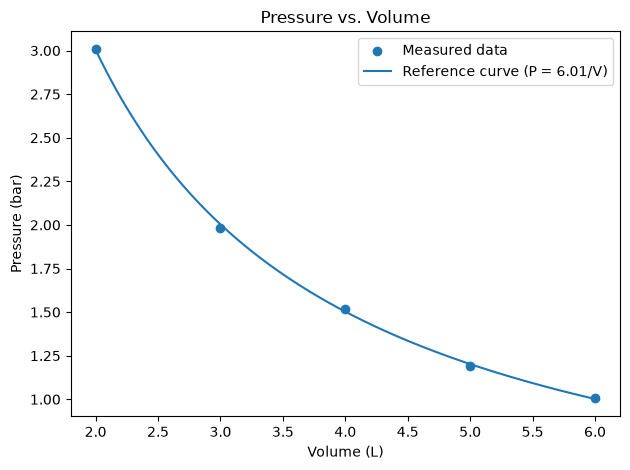

In [2]:
import matplotlib.pyplot as plt

volume_L = [2, 3, 4, 5, 6]
pressure_bar = [3.01, 1.98, 1.52, 1.19, 1.01]

# Calculate the mean of P * V
pv_sum = 0
for i in range(len(volume_L)):
    pv_sum += pressure_bar[i] * volume_L[i]

k = pv_sum / len(volume_L)
print(f"Mean k: {k:.2f} bar·L")

# Generate points for the reference curve P = k / V
volume_curve = []
pressure_curve = []

for i in range(200):
    volume = 2 + i * (6 - 2) / 199
    volume_curve.append(volume)
    pressure_curve.append(k / volume)

plt.scatter(volume_L, pressure_bar, label="Measured data")
plt.plot(volume_curve, pressure_curve, label=f"Reference curve (P = {k:.2f}/V)")

plt.title("Pressure vs. Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.tight_layout()
plt.show()